# 2. Cyg X-1 around its orbit

X-ray binaries are one of the most natural targets for an X-ray interferometer. `XRBinary` builds one from 3-D parts; here we use Cyg X-1's system parameters (Miller-Jones et al. 2021: D = 2.22 kpc, M_BH = 21.2 M☉, M_donor = 40.6 M☉, R_donor = 22.3 R☉, i = 27.5°, P = 5.6 d) and wind (Hanke et al. 2009: Ṁ = 3×10⁻⁶ M☉/yr, v∞ = 2100 km/s):

* a Roche-lobe-filling **donor** (opaque body) that reflects the corona from its irradiated face;
* a flared **disc** (opaque body) that reflects the corona and shadows part of the donor;
* the **corona** (a lamp at the compact object) and the donor's beta-law **wind**, which scatters the corona's light, emits Fe XXV/XXVI lines and absorbs (only where it is not fully ionised).

`XRBinary` is a preset of `System3D`, so every layer carries Doppler shifts, light-travel delays and the absorbing and electron columns both in front of it and between it and the corona.

At 2.22 kpc the binary separation (0.24 AU) is 110 µas and the donor 47 µas in radius, so the whole system spans ~300 µas: comparable to the ~190 µas beam of the 10-baseline instrument bundled with XRISALIS (baselines up to 1 m).

In [1]:
import warnings

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

import xrimodel as xm
from xrimodel.engine import Scene, XRBinary
from xrimodel.units import UAS_PER_RAD

# rays grazing the donor reach electron-scattering depths of ~0.5 in the dense wind base;
# the renderer warns that single scattering is approximate there
warnings.filterwarnings("ignore", message=".*electron-scattering optical depth.*")

gamma = 1.7
norm = 7.4e-9 / xm.powerlaw(xm.energy_grid(), gamma, 1.0).energy_flux(0.5, 10.0)
corona = {"kind": "powerlaw", "gamma": gamma, "norm": norm}   # F(0.5-10 keV) = 7.4e-9 erg/s/cm2
grid = xm.RegularGrid(nx=160, ny=160, scale=2.0)               # 2 uas pixels, 320 uas across


def render(phase, **kw):
    # a finer shadow grid than the default keeps the donor's shadow edge in the wind smooth
    scene = Scene(ra=299.590315, dec=35.201604, distance_pc=2220.0, grid=grid)
    b = scene.add(XRBinary("cyg", corona, phase=phase, column_grid=(96, 192, 128), **kw))
    return scene.render(), b


def extended(model):
    return [L for L in model.layers if L.grid.n > 1]


def band_image(model, lo, hi):
    tot = np.zeros(grid.n)
    for L in extended(model):
        tot += xm.specmap_projection(L, edges=np.linspace(lo, hi, 41))[1]
    return grid.to_image(tot) / (grid.scale / UAS_PER_RAD) ** 2   # photons/s/cm2/sr


half = grid.nx / 2 * grid.scale
ext = [half, -half, -half, half]


def sky_donor(phase):
    # the donor's centre on the sky (uas from the compact object)
    b = XRBinary("cyg", corona, phase=phase)
    f = b.frame()
    u_a, u_b = b.sky_axes()
    d = f["donor"] - f["bh"]
    cm_per_uas = 2220.0 * 3.0857e18 / UAS_PER_RAD
    return (d @ f["e_a"] * u_a + d @ f["e_b"] * u_b) / cm_per_uas

## The system at four phases

Phase 0 is superior conjunction of the compact object (when it is behind the donor). Here we show the extended (reprocessed) light only; the cross marks the compact object, where the corona sits. The donor's lit face turns towards us at phase 0.5, and the orbit runs counterclockwise on the sky.

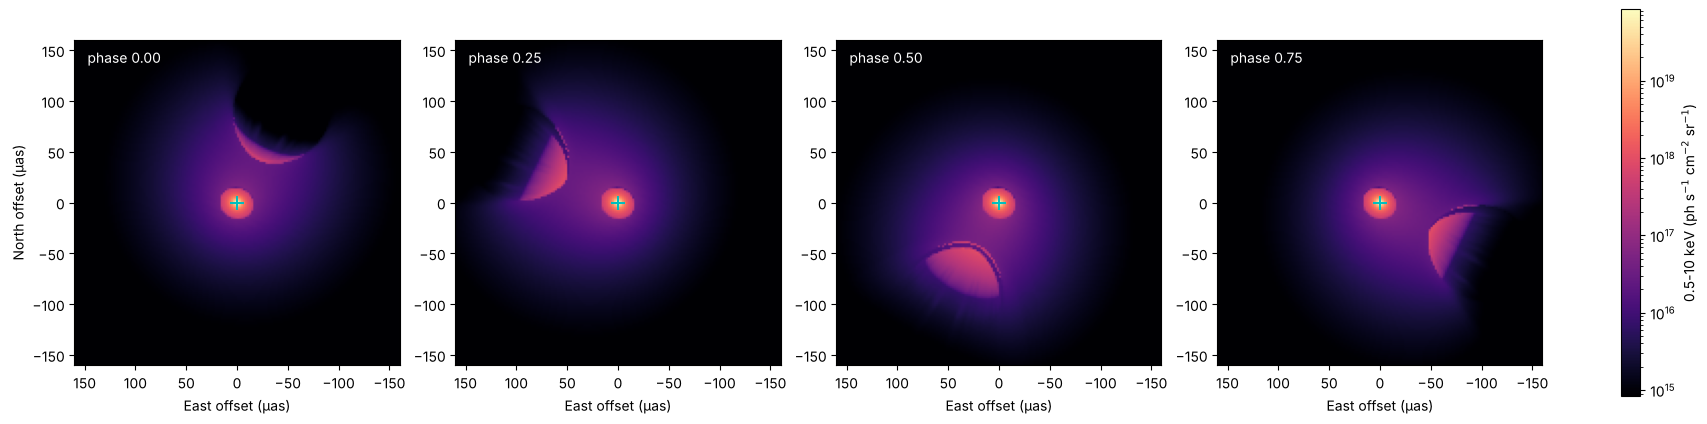

In [2]:
phases = (0.0, 0.25, 0.5, 0.75)
models = {}
for ph in phases:
    models[ph], b = render(ph)

imgs = {ph: band_image(models[ph], 0.5, 10.0) for ph in phases}
vmax = max(i.max() for i in imgs.values())
fig, ax = plt.subplots(1, 4, figsize=(17, 4.2), constrained_layout=True)
for a, ph in zip(ax, phases):
    im = a.imshow(np.where(imgs[ph] > 0, imgs[ph], np.nan), origin="lower", extent=ext,
                  cmap="magma", norm=LogNorm(vmin=vmax * 1e-5, vmax=vmax))
    a.plot(0, 0, "+", color="c", ms=10, mew=1.5)
    a.text(0.04, 0.93, f"phase {ph:.2f}", transform=a.transAxes, color="w")
    a.set_xlabel("East offset (µas)")
ax[0].set_ylabel("North offset (µas)")
fig.colorbar(im, ax=ax, label="0.5-10 keV (ph s$^{-1}$ cm$^{-2}$ sr$^{-1}$)", fraction=0.02)

## How much light, and how much column, around the orbit

Here we show the fluxes of the reprocessed components relative to the corona, and the absorbing column to the corona itself (ISM excluded). The column is highest at superior conjunction, when we look at the compact object through the donor's wind.

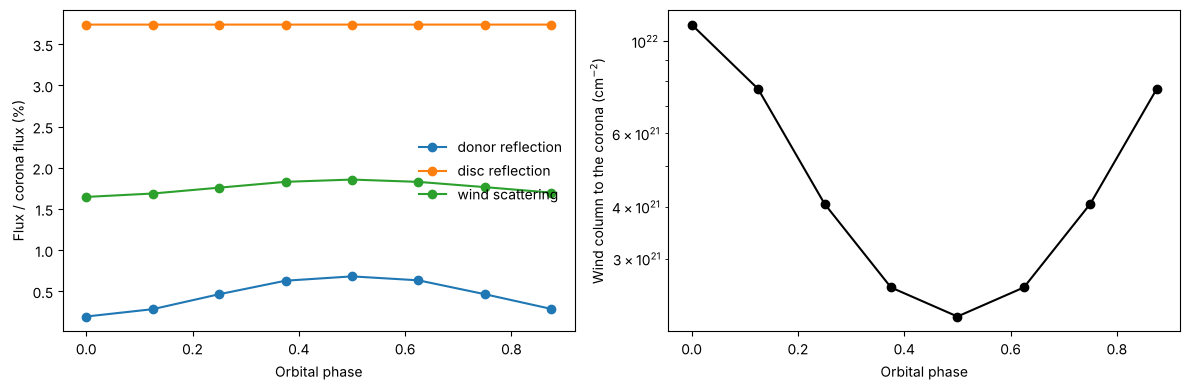

In [3]:
grid_coarse = xm.RegularGrid(nx=80, ny=80, scale=4.0)
orbit = np.linspace(0.0, 1.0, 9)[:-1]
rows = []
for ph in orbit:
    scene = Scene(ra=299.590315, dec=35.201604, distance_pc=2220.0, grid=grid_coarse)
    b = scene.add(XRBinary("cyg", corona, phase=ph))
    m = scene.render()
    cor = m.layer("cyg_corona").mean_photon_flux()
    fx = {k: sum(L.mean_photon_flux() for L in m.layers if L.name.startswith(f"cyg_{k}")) / cor
          for k in ("star", "disc", "wind")}
    rows.append((ph, fx["star"], fx["disc"], fx["wind"], b._last_frame["col_bh"]))
rows = np.array(rows)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for k, lab in zip(range(1, 4), ("donor reflection", "disc reflection", "wind scattering")):
    ax[0].plot(rows[:, 0], 100 * rows[:, k], "o-", label=lab)
ax[0].set_xlabel("Orbital phase"); ax[0].set_ylabel("Flux / corona flux (%)")
ax[0].legend(frameon=False, loc="center right")
ax[1].semilogy(rows[:, 0], rows[:, 4], "ko-")
ax[1].set_xlabel("Orbital phase"); ax[1].set_ylabel("Wind column to the corona (cm$^{-2}$)")
fig.tight_layout()

The disc reflection comes mostly from within ~1 µas of the compact object, so on this coarse grid it is only a rough estimate. For accurate disc fluxes, render on a `QuadtreeGrid` refined towards the compact object instead (see `tests/test_binary.py`).

## Spectra, shifts and delays at phase 0.5

Here we show each component's (absorbed) spectrum, the flux-weighted line-of-sight velocity of the extended light and its delay after the corona. The donor's reflection is strongly absorbed below ~3 keV: the corona's light reaches the irradiated face through the dense, weakly ionised base of the wind, and that column is added to the reflected light (`absorb_illumination=True`). The velocity map is dominated by the wind (±2000 km/s at large distances), while the donor and disc show the orbital motion.

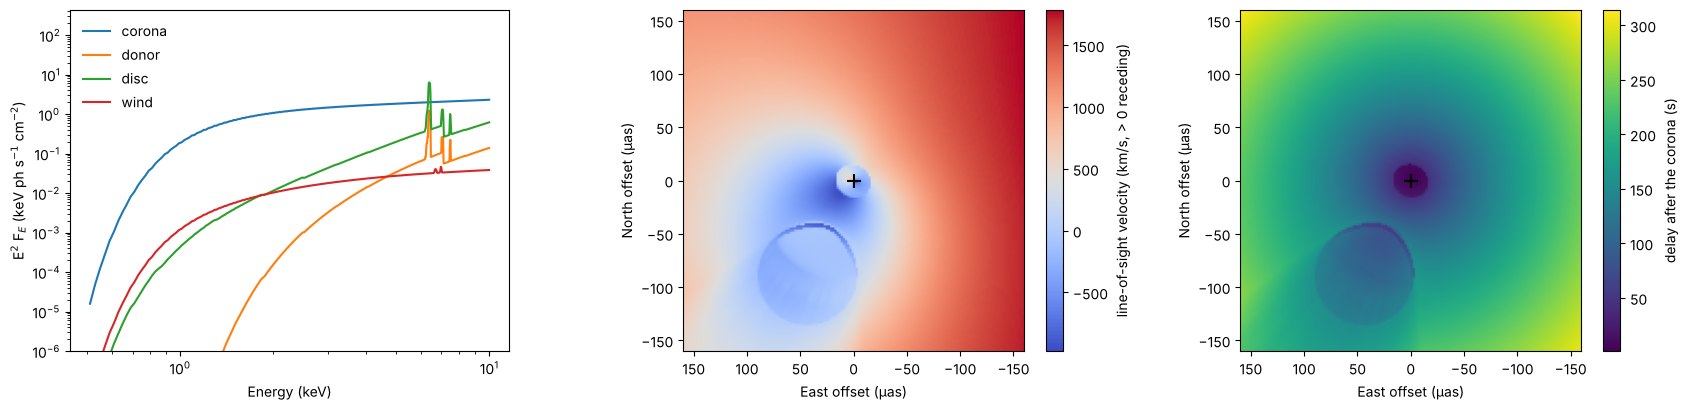

In [4]:
m = models[0.5]
e = xm.energy_grid(0.5, 10.0, 0.02)
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
groups = {"corona": ["cyg_corona"], "donor": ["cyg_star"], "disc": ["cyg_disc"],
          "wind": [L.name for L in m.layers if L.name.startswith("cyg_wind")]}
for lab, names in groups.items():
    tot = sum(xm.specmap_projection(m.layer(n), edges=e)[0].values for n in names)
    ax[0].loglog(0.5 * (e[1:] + e[:-1]), tot * (0.5 * (e[1:] + e[:-1])) ** 2, label=lab)
ax[0].set_xlabel("Energy (keV)"); ax[0].set_ylabel("E$^2$ F$_E$ (keV ph s$^{-1}$ cm$^{-2}$)")
ax[0].legend(frameon=False); ax[0].set_ylim(1e-6, None)

layers = extended(m)
w = sum(L.maps["NORM"] for L in layers)
safe = np.where(w > 0, w, 1)
for a, key, cmap, lab in [(ax[1], "G", "coolwarm", "line-of-sight velocity (km/s, > 0 receding)"),
                          (ax[2], "DELAY", "viridis", "delay after the corona (s)")]:
    q = sum(L.maps["NORM"] * L.maps[key] for L in layers) / safe
    if key == "G":
        q = (1 - q) * 2.998e5
    im = a.imshow(grid.to_image(np.where(w > 0, q, np.nan)), origin="lower", extent=ext, cmap=cmap)
    a.plot(0, 0, "+", color="k", ms=10, mew=1.5)
    fig.colorbar(im, ax=a, label=lab, fraction=0.046)
    a.set_xlabel("East offset (µas)"); a.set_ylabel("North offset (µas)")
fig.tight_layout()

## Reverberation response

Here we show the flux-weighted distribution of delays of each reprocessed component, i.e. the transfer function summed over energy. The disc responds within half a minute, the donor after 1.5-2.5 minutes, and the wind over a broad range of delays.

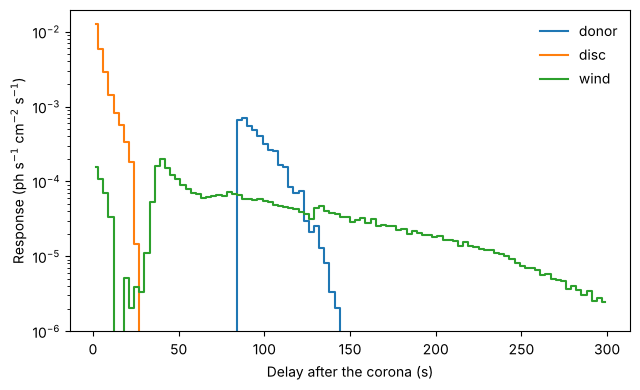

In [5]:
d_edges = np.linspace(0.0, 300.0, 101)
e_edges = np.linspace(0.5, 10.0, 20)
fig, ax = plt.subplots(figsize=(6.5, 4))
for lab, names in list(groups.items())[1:]:
    psi = sum(xm.transfer_function(m.layer(n), e_edges, d_edges) for n in names)
    ax.step(0.5 * (d_edges[1:] + d_edges[:-1]), psi.sum(axis=0) / np.diff(d_edges), where="mid",
            label=lab)
ax.set_yscale("log"); ax.set_ylim(1e-6, None)
ax.set_xlabel("Delay after the corona (s)"); ax.set_ylabel("Response (ph s$^{-1}$ cm$^{-2}$ s$^{-1}$)")
ax.legend(frameon=False)
fig.tight_layout()

## Focused and clumpy winds

The wind has two further options. **Focusing** towards the compact object (density ×(1 + A) along the binary axis, falling off over `focus_width`) has been inferred for Cyg X-1, and **clumping** puts the gas in a fraction `clump_f_vol` of the volume, in cells that grow with distance from the donor (the mean density is unchanged). We show both at phase 0, looking at the compact object through the wind, on a common colour scale. The dark disc is the donor's night side: the wind in front of it lies in the donor's shadow. Clumping makes the scattered light patchy (the cells are large here for visibility) and, because dense clumps are less ionised, raises the absorbing column on average.

smooth   wind scattering 1.60% of the corona, column to the corona 1.10e+22 cm^-2
focused  wind scattering 3.48% of the corona, column to the corona 2.28e+22 cm^-2
clumped  wind scattering 1.53% of the corona, column to the corona 2.32e+22 cm^-2


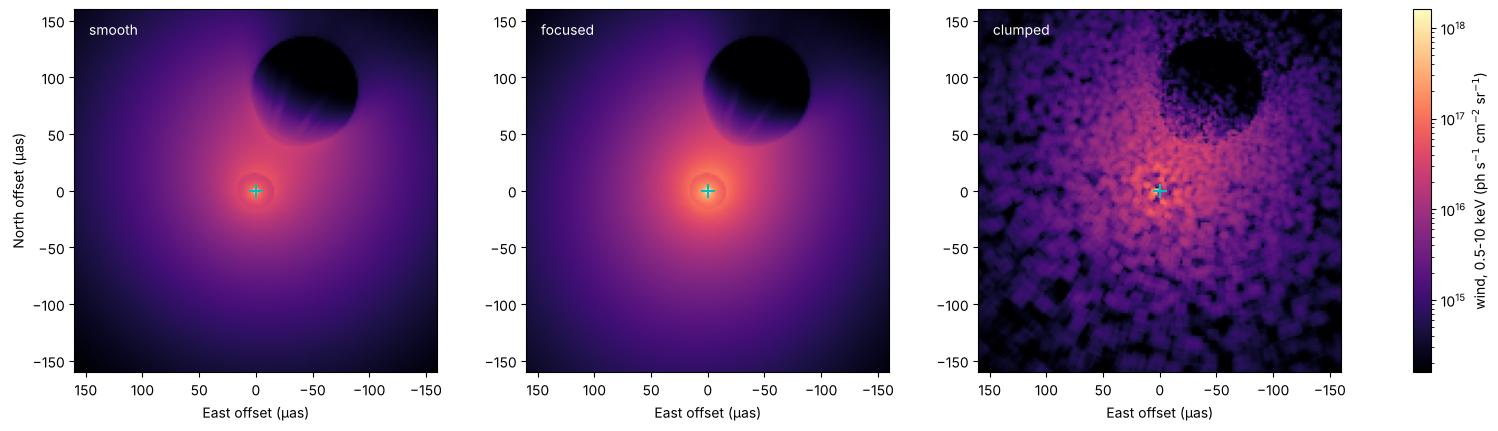

In [6]:
variants = {"smooth": {}, "focused": dict(focus_amp=3.0, focus_width=25.0),
            "clumped": dict(clump_f_vol=0.1, clump_size=0.05, clump_seed=3)}
out, wimg = {}, {}
for lab, kw in variants.items():
    mv, bv = render(0.0, **kw)
    wind = [L for L in mv.layers if L.name.startswith("cyg_wind")]
    tot = sum(xm.specmap_projection(L, edges=np.linspace(0.5, 10, 41))[1] for L in wind)
    wimg[lab] = grid.to_image(tot) / (grid.scale / UAS_PER_RAD) ** 2
    cor = mv.layer("cyg_corona").mean_photon_flux()
    out[lab] = (sum(L.mean_photon_flux() for L in wind) / cor, bv._last_frame["col_bh"])

vmax = max(i.max() for i in wimg.values())
cmap = plt.get_cmap("magma").copy()
cmap.set_bad(cmap(0.0))
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2), constrained_layout=True)
for a, lab in zip(ax, variants):
    img = wimg[lab]
    im = a.imshow(np.where(img > 0, img, np.nan), origin="lower", extent=ext, cmap=cmap,
                  norm=LogNorm(vmin=vmax * 1e-4, vmax=vmax))
    a.plot(0, 0, "+", color="c", ms=10, mew=1.5)
    a.text(0.04, 0.93, lab, transform=a.transAxes, color="w")
    a.set_xlabel("East offset (µas)")
ax[0].set_ylabel("North offset (µas)")
fig.colorbar(im, ax=ax, label="wind, 0.5-10 keV (ph s$^{-1}$ cm$^{-2}$ sr$^{-1}$)", fraction=0.02)
for lab, (f, col) in out.items():
    print(f"{lab:8s} wind scattering {100 * f:.2f}% of the corona, column to the corona {col:.2e} cm^-2")

## Through XRISALIS

Now we observe the model at superior conjunction (phase 0) and at phase 0.5 with the 10-baseline instrument bundled with XRISALIS (beam ~190 µas), at Cyg X-1's real brightness. We show three views for illustration: 200 s of all the light, where the corona dominates; 2 ks of the reprocessed light (disc, donor, wind); and 20 ks of the donor's reflection alone. In a real observation the fainter parts would of course have to be separated from the corona's point-spread function first. These use `xri_helpers.observe` (see the quickstart).

phase 0.0, all light: 127380 events in 200 s


phase 0.0, reprocessed: 78962 events in 2000 s


phase 0.0, donor only: 15991 events in 20000 s


phase 0.5, all light: 206422 events in 200 s


phase 0.5, reprocessed: 100896 events in 2000 s


phase 0.5, donor only: 104017 events in 20000 s


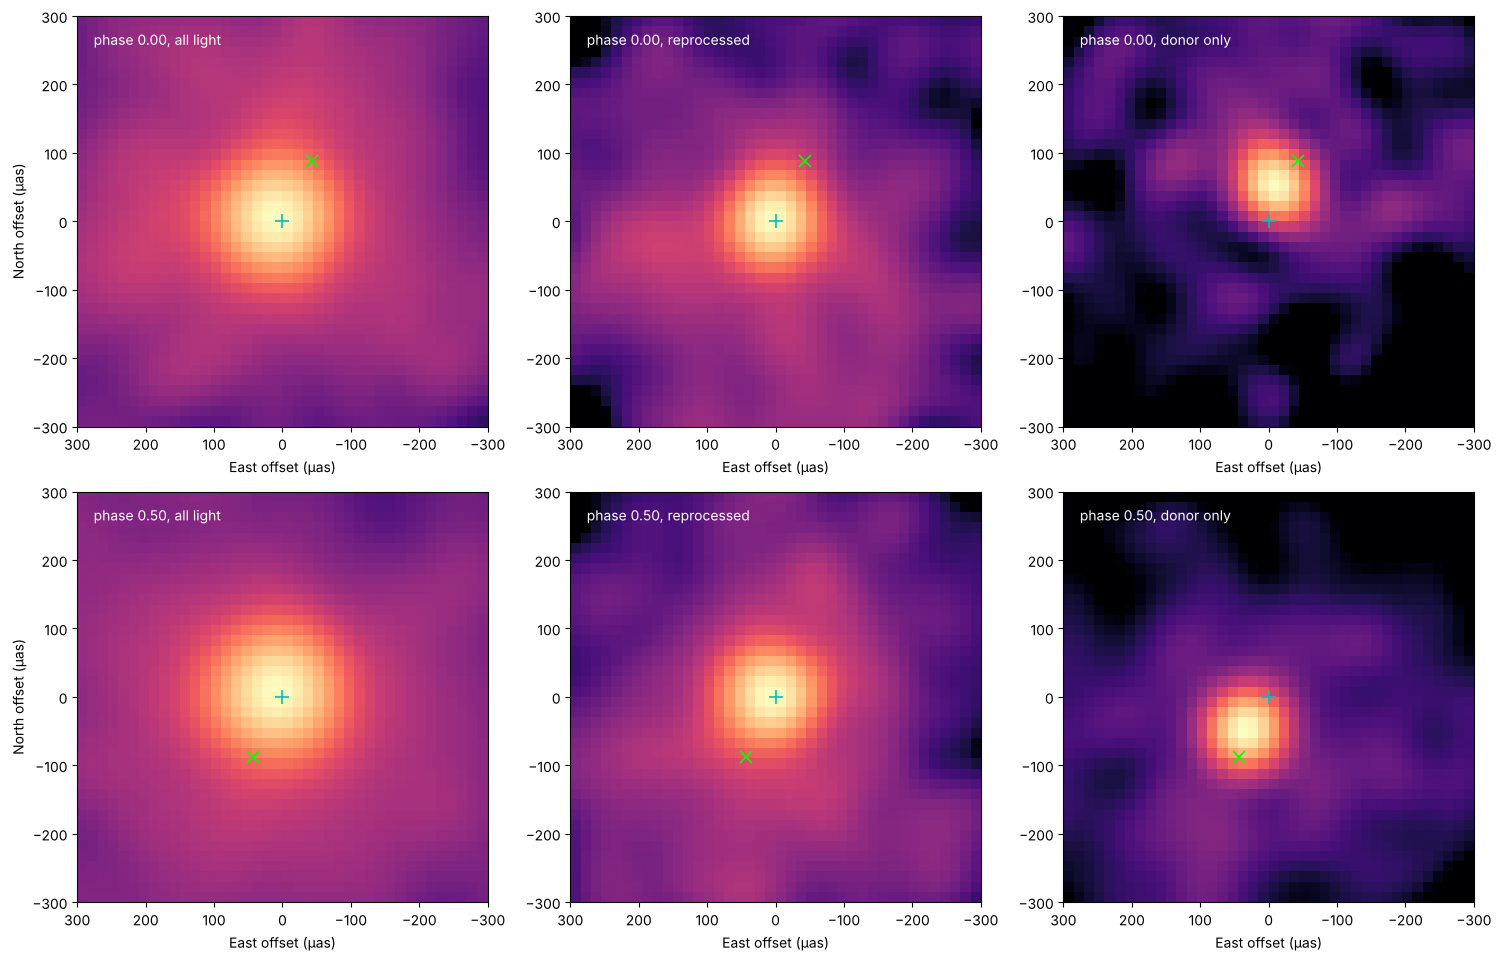

In [7]:
try:
    import xri_helpers as xri
except ImportError as err:   # XRISALIS not installed
    xri = None
    print("skipping:", err)

if xri is not None:
    views = [("all light", lambda n: True, 200.0, 0.4),
             ("reprocessed", lambda n: n != "cyg_corona", 2000.0, 0.5),
             ("donor only", lambda n: n == "cyg_star", 20000.0, 0.7)]
    fig, ax = plt.subplots(2, 3, figsize=(15, 9.5), constrained_layout=True)
    for row, ph in enumerate((0.0, 0.5)):
        donor = sky_donor(ph)
        for col, (lab, keep, t_exp, gam) in enumerate(views):
            obs = xri.observe(xri.subset(models[ph], keep), t_exp, fov_arcsec=0.0012,
                              seed=10 * row + col)
            print(f"phase {ph}, {lab}: {len(obs['events'])} events in {t_exp:.0f} s")
            a = ax[row, col]
            xri.show(a, obs, lim=300, label=f"phase {ph:.2f}, {lab}", gamma=gam)
            a.plot(0, 0, "+", color="c", ms=10, mew=1.2)
            a.plot(*donor, "x", color="lime", ms=8, mew=1.2)
        ax[row, 0].set_ylabel("North offset (µas)")

Cyan marks the compact object and green the donor's centre. With all the light, the image is simply the corona's point-spread function. The reprocessed light is dominated by the disc's reflection, unresolved at the compact object, with the wind's halo around it. The donor's reflection alone follows the donor around the orbit, and peaks between the donor's centre and the compact object because the lit face looks towards the compact object. Each panel is normalised to its own peak: at phase 0, when we mostly see the donor's night side, the reflection gives six times fewer photons than at phase 0.5.